# PDF와 표·OCR

**이 노트북에서 할 일**

1. 01절과 같은 E01.pdf에서 표가 있는 쪽을 기본 읽기로 보고 값의 개수를 셉니다.
2. 같은 쪽을 표 읽기로 읽어 행과 칸을 얻고, 칸마다 머리글을 붙입니다.
3. 같은 문서의 스캔본을 읽어 글자가 없는 쪽을 OCR 후보로 가릅니다.

**준비물** — API 키가 필요 없습니다. 모델과 임베딩에는 요청을 한 번도 보내지 않습니다.
첫 셀의 패키지 설치만 인터넷을 씁니다.
그래서 예상 비용은 0달러입니다. 실행 시간은 패키지 설치를 빼면 10초 안팎입니다.

데이터는 파일 두 개입니다. 폴더 `labs/data/rag-corpus/`의 `pdf/easy/E01.pdf`와 `pdf/scanned/S01-E01-scan.pdf`입니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 설명합니다.
파일 두 개 찾기, 기본 읽기에 보이는 표, 표 읽기, 머리글 붙이기, 출처 기록입니다.
7절 값 바꿔 보기와 8~9절 Before·After는 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다. pypdf 6.18.0, pdfplumber 0.11.10, langchain-core 1.6.2입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다. 다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

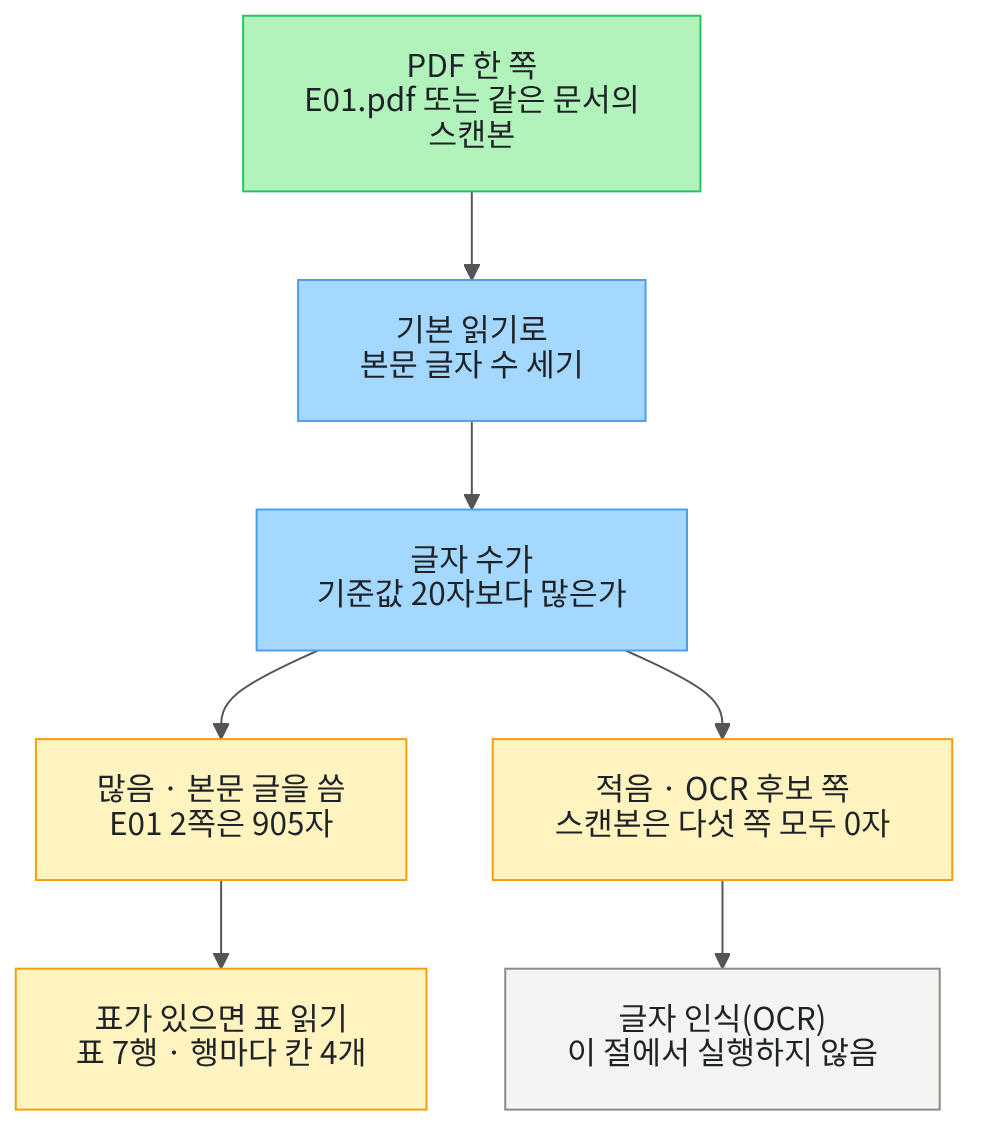

쪽마다 본문 글자 수를 먼저 셉니다. 그 값에 따라 다음 단계가 세 갈래로 갈립니다.
글자가 넉넉한 쪽은 본문 글을 쓰고, 표가 있으면 표 읽기를 한 번 더 합니다.
글자가 거의 없는 쪽은 OCR 후보로 따로 모읍니다. 회색 상자는 이 절에서 실행하지 않는 단계입니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01절에서 쓴 pypdf와 `Document`에 표를 읽는 pdfplumber를 더합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "pdfplumber==0.11.10" "langchain-core==1.6.2"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("pdfplumber:", version("pdfplumber"))
print("langchain-core:", version("langchain-core"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.18.0
pdfplumber: 0.11.10
langchain-core: 1.6.2


**결과 읽기** — 출력 줄은 `pypdf: 6.18.0`, `pdfplumber: 0.11.10`, `langchain-core: 1.6.2` 세 줄입니다.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
라이브러리 pdfplumber는 글자의 자리와 표의 칸 경계를 함께 다루는 도구입니다.
01절에서 쓴 `os`·`Path`·`PdfReader`·`Document`는 그대로 씁니다.

In [2]:
# 파일 찾기·경로 속성 읽기·PDF 읽기·표 읽기·문서 객체 만들기에 쓸 이름을 불러옵니다
import os
from pathlib import Path

import pdfplumber
from pypdf import PdfReader
from langchain_core.documents import Document

## 2. 이 절에서 읽을 파일 두 개 찾기

01절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [3]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 읽을 파일 두 개의 경로를 만듭니다.
하나는 01절에서 읽은 E01.pdf이고, 하나는 같은 문서를 스캔해 만든 파일입니다.
스캔본은 종이를 사진으로 찍어 PDF로 묶은 파일이라 본문이 그림으로만 들어 있습니다.

In [4]:
# 읽을 파일 두 개의 경로를 만들고 파일이 있는지 확인합니다
corpus_path = root_path + "/labs/data/rag-corpus"
pdf_path = corpus_path + "/pdf/easy/E01.pdf"
scan_path = corpus_path + "/pdf/scanned/S01-E01-scan.pdf"
print("E01 파일이 있는가:", os.path.exists(pdf_path))
print("스캔본 파일이 있는가:", os.path.exists(scan_path))
print("스캔본 파일 이름:", Path(scan_path).name)

E01 파일이 있는가: True
스캔본 파일이 있는가: True
스캔본 파일 이름: S01-E01-scan.pdf


**결과 읽기** — 출력 줄은 `E01 파일이 있는가: True`와 `스캔본 파일이 있는가: True`입니다.
마지막 줄 `스캔본 파일 이름: S01-E01-scan.pdf`에서 이름 가운데의 `E01`이 원본 문서 이름입니다.
이 파일은 01절에서 센 `scanned` 폴더의 3건 가운데 하나입니다.

## 3. 기본 읽기에 표가 보이는 모습

01절에서 E01 2쪽을 기본 읽기로 읽어 905자를 얻었습니다.
그 쪽에는 자료실별 이용 시간을 적은 표가 하나 있습니다.
기본 읽기는 표의 선을 보지 않고 글자만 순서대로 이어 붙입니다.

실행 전에 예상합니다. 표의 한 행이 한 줄로 이어져 나올 것입니다.

In [5]:
# 01절과 같은 기본 읽기로 E01 2쪽을 읽고 줄 목록으로 나눕니다
reader = PdfReader(pdf_path)
plain_text = reader.pages[1].extract_text()
plain_lines = plain_text.split("\n")
print("기본 읽기 글자 수:", len(plain_text))
print("기본 읽기 줄 수:", len(plain_lines))
print("마지막 줄:", plain_lines[-1])

기본 읽기 글자 수: 905
기본 읽기 줄 수: 26
마지막 줄: 2


**결과 읽기** — 출력 줄은 `기본 읽기 글자 수: 905`와 `기본 읽기 줄 수: 26`입니다.
01절 4절에서 본 값과 같습니다. 같은 파일을 같은 방법으로 읽었기 때문입니다.
마지막 줄은 쪽 번호 `2`만 있는 줄입니다.

다음 셀은 표의 머리글 줄과 그 아래 첫 행 줄을 찾습니다.
그리고 줄을 빈칸으로 나누어 값이 몇 개인지 셉니다.
메서드 `split(" ")`은 글을 빈칸 자리에서 잘라 목록으로 만듭니다.

In [6]:
# 표의 머리글 줄과 첫 행 줄을 찾아 빈칸으로 나눈 값의 개수를 셉니다
header_line = ""
first_row_line = ""
for line in plain_lines:
    if "구역 평일" in line:
        header_line = line
    if "종합자료실" in line:
        first_row_line = line
header_values = header_line.split(" ")
first_row_values = first_row_line.split(" ")
print("머리글 줄:", header_line)
print("머리글 줄의 값 개수:", len(header_values))
print("첫 행 줄:", first_row_line)
print("첫 행 줄의 값 개수:", len(first_row_values))

머리글 줄: 구역 평일 주말 비고
머리글 줄의 값 개수: 4
첫 행 줄: 종합자료실(2층) 09:00~22:00 09:00~18:00
첫 행 줄의 값 개수: 3


**결과 읽기** — 출력 줄 `머리글 줄: 구역 평일 주말 비고`는 값이 네 개입니다.
그래서 `머리글 줄의 값 개수: 4`입니다.
그런데 `첫 행 줄: 종합자료실(2층) 09:00~22:00 09:00~18:00`은 값이 세 개뿐입니다.
출력 `첫 행 줄의 값 개수: 3`이 그 수입니다.

원본 표에서 이 행의 비고 칸에는 값이 없습니다. 기본 읽기는 값이 없는 칸을 아무 표시 없이 지나갑니다.
그래서 이 줄만 보면 어느 칸이 비었는지 알 수 없습니다.

## 4. 표 읽기로 행과 칸 얻기

라이브러리 pdfplumber는 쪽에 그려진 선의 자리를 보고 표의 칸 경계를 찾습니다.
메서드 `extract_tables()`는 찾은 표마다 행 목록을 만들고, 행마다 칸 목록을 넣어 반환합니다.
즉 표 목록 안에 행 목록이 있고, 행 목록 안에 칸의 글이 있는 세 겹 목록입니다.

`with` 줄은 파일을 다 쓰고 나면 자동으로 닫습니다.
Ch 2 05절에서 파일을 열 때 배운 모양이고, 이번에는 라이브러리 객체에 씁니다.

In [7]:
# pdfplumber로 같은 2쪽을 열어 찾은 표의 수와 행·칸을 봅니다
with pdfplumber.open(pdf_path) as pdf:
    selected_page = pdf.pages[1]
    tables = selected_page.extract_tables()
first_table = tables[0]
header_row = first_table[0]
print("찾은 표의 수:", len(tables))
print("첫 표의 행 수:", len(first_table))
print("머리글 행:", header_row)
print("첫 행:", first_table[1])
print("첫 행의 칸 수:", len(first_table[1]))

찾은 표의 수: 1
첫 표의 행 수: 7
머리글 행: ['구역', '평일', '주말', '비고']
첫 행: ['종합자료실(2층)', '09:00~22:00', '09:00~18:00', '']
첫 행의 칸 수: 4


**결과 읽기** — 출력 줄은 `찾은 표의 수: 1`과 `첫 표의 행 수: 7`입니다.
머리글 한 행에 구역 여섯 행을 더해 일곱 행입니다.
출력 `머리글 행: ['구역', '평일', '주말', '비고']`는 칸 네 개를 따로 담은 목록입니다.

다음 줄 `첫 행: ['종합자료실(2층)', '09:00~22:00', '09:00~18:00', '']`을 보세요.
마지막 칸이 빈 글 `''`로 남아 있어서 `첫 행의 칸 수: 4`입니다.
기본 읽기에서 사라졌던 「값이 없는 칸」이 표 읽기에서는 자리로 남습니다.

## 5. 칸마다 머리글 붙이기

칸 목록만으로는 검색에 쓸 수 없습니다. 값이 어느 칸의 값인지 글에 적혀 있지 않기 때문입니다.
그래서 행마다 머리글을 칸 앞에 붙여 한 줄로 만듭니다.
다음 셀은 머리글 하나와 칸 하나를 받아 짝지은 글을 만드는 함수를 정의합니다.

In [8]:
# 머리글 하나와 칸 하나를 받아 「머리글: 값」 꼴로 짝지은 글을 만들어 반환합니다
def make_cell_text(label, cell):
    value = cell
    if value == "":
        value = "(값 없음)"
    return label + ": " + value

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

값이 없는 칸은 `(값 없음)`으로 바꿔 적습니다. 값이 없다는 사실도 검색 결과에서 읽히게 하려는 것입니다.

다음 셀은 위 함수를 칸마다 불러 한 행을 한 줄 글로 만듭니다.
변수 `cell_number`는 지금 몇 번째 칸인지 세는 번호입니다. 그 번호로 머리글 행에서 짝이 되는 말을 꺼냅니다.

In [9]:
# 머리글 행과 표의 한 행을 받아 칸마다 머리글을 붙인 한 줄 글을 만들어 반환합니다
def make_row_text(header_row, row):
    row_text = ""
    cell_number = 0
    for cell in row:
        cell_text = make_cell_text(header_row[cell_number], cell)
        if row_text != "":
            row_text = row_text + " / "
        row_text = row_text + cell_text
        cell_number = cell_number + 1
    return row_text

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

칸 사이는 ` / `로 띄웁니다. 첫 칸 앞에는 붙이지 않으려고 글이 비어 있는지 먼저 봅니다.

In [10]:
# 머리글 없는 줄과 머리글을 붙인 줄을 견줍니다
first_row_text = make_row_text(header_row, first_table[1])
second_row_text = make_row_text(header_row, first_table[2])
print("기본 읽기 줄:", first_row_line)
print("머리글을 붙인 줄:", first_row_text)
print("둘째 행:", second_row_text)

기본 읽기 줄: 종합자료실(2층) 09:00~22:00 09:00~18:00
머리글을 붙인 줄: 구역: 종합자료실(2층) / 평일: 09:00~22:00 / 주말: 09:00~18:00 / 비고: (값 없음)
둘째 행: 구역: 어린이자료실(1층) / 평일: 09:00~18:00 / 주말: 09:00~18:00 / 비고: 보호자 동반 권장


**결과 읽기** — 출력 줄 `머리글을 붙인 줄:` 뒤에 `구역: 종합자료실(2층) / 평일: 09:00~22:00 / 주말: 09:00~18:00 / 비고: (값 없음)`이 보입니다.
바로 위 `기본 읽기 줄:`과 견주면 머리글 네 개와 `(값 없음)`이 늘어났습니다.

`둘째 행:` 줄도 보세요. 평일과 주말 값이 `09:00~18:00`으로 같은데 이제는 어느 쪽인지 적혀 있습니다.
이 행의 비고 칸에는 `보호자 동반 권장`이 들어 있습니다.

## 6. 다섯 칸 출처 기록에 읽은 방법 적기

01절에서 만든 함수 두 개를 같은 코드로 가져옵니다.
앞 함수는 파일 경로·쪽 번호·읽은 방법을 받아 다섯 칸 기록을 만듭니다.
뒤 함수는 그 기록에서 두 칸만 읽어 출처 표시를 만듭니다.

In [11]:
# 파일 경로·쪽 번호·읽은 방법 이름을 받아 다섯 칸 출처 기록을 만들어 반환합니다(01절 5절과 같은 코드)
def make_source_record(file_path, page, parser):
    path_object = Path(file_path)
    suffix = path_object.suffix
    file_type = suffix.replace(".", "").lower()
    record = {"doc_id": path_object.stem, "source": path_object.name,
              "file_type": file_type, "parser": parser, "page": page}
    return record

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

01절에서는 `parser` 칸에 `pypdf-plain`을 적었습니다.
이번에는 같은 쪽을 pdfplumber로 읽었으므로 `pdfplumber`를 적습니다.
실습 폴더 모듈도 이 읽기에 같은 이름을 씁니다.

In [12]:
# 문서 청크 하나를 받아 [E01 p.2] 모양의 출처 표시를 만들어 반환합니다(01절 6절과 같은 코드)
def make_source_mark(chunk):
    doc_id = chunk.metadata["doc_id"]
    page = chunk.metadata["page"]
    source_mark = f"[{doc_id} p.{page}]"
    return source_mark

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

다음 셀은 머리글 아래 행마다 `Document` 하나를 만듭니다.
본문 글은 머리글을 붙인 줄이고, 메타데이터는 다섯 칸 기록입니다.
변수 `row_number`가 1인 첫 행은 머리글이라 건너뜁니다.

In [13]:
# 표의 머리글 아래 행마다 Document 하나를 만들어 목록에 담습니다
table_record = make_source_record(pdf_path, 2, "pdfplumber")
row_documents = []
row_number = 1
for row in first_table:
    if row_number > 1:
        row_text = make_row_text(header_row, row)
        row_document = Document(page_content=row_text, metadata=table_record)
        row_documents.append(row_document)
    row_number = row_number + 1
print("행 Document 수:", len(row_documents))
print("첫 행의 출처 표시:", make_source_mark(row_documents[0]))
print("첫 행의 기록:", row_documents[0].metadata)

행 Document 수: 6
첫 행의 출처 표시: [E01 p.2]
첫 행의 기록: {'doc_id': 'E01', 'source': 'E01.pdf', 'file_type': 'pdf', 'parser': 'pdfplumber', 'page': 2}


**결과 읽기** — 출력 줄은 `행 Document 수: 6`입니다. 일곱 행에서 머리글 한 행을 뺀 수입니다.
다음 줄 `첫 행의 출처 표시: [E01 p.2]`는 01절과 글자까지 같습니다.
마지막 줄 `첫 행의 기록:` 뒤에 `{'doc_id': 'E01', 'source': 'E01.pdf', 'file_type': 'pdf', 'parser': 'pdfplumber', 'page': 2}`가 보입니다.
칸 이름은 01절과 같고 `parser` 값만 달라졌습니다.

여섯 기록은 글자까지 같습니다. 표의 몇 번째 행인지는 이 기록에 없고, 03절에서 `row` 칸으로 그 자리를 적습니다.

## 7. 값 하나만 바꿔 보기

바꾸는 값은 쪽 번호 하나입니다. 2쪽에서 4쪽으로 바꿉니다.
E01 4쪽에는 시설 예약을 적은 표가 있습니다.

실행 전에 예상합니다. 머리글이 달라지고 행 수도 달라질 것입니다.

In [14]:
# 같은 코드에서 쪽 번호만 4로 바꿔 다른 표를 읽습니다
with pdfplumber.open(pdf_path) as pdf:
    fourth_page = pdf.pages[3]
    fourth_tables = fourth_page.extract_tables()
fourth_table = fourth_tables[0]
fourth_header = fourth_table[0]
print("4쪽에서 찾은 표의 수:", len(fourth_tables))
print("4쪽 첫 표의 행 수:", len(fourth_table))
print("4쪽 머리글 행:", fourth_header)
print("4쪽 첫 행:", make_row_text(fourth_header, fourth_table[1]))

4쪽에서 찾은 표의 수: 1
4쪽 첫 표의 행 수: 5
4쪽 머리글 행: ['시설', '정원', '이용료(시간당)', '예약 방법']
4쪽 첫 행: 시설: 강당(지하 1층) / 정원: 150명 / 이용료(시간당): 30,000원 / 예약 방법: 14일 전 홈페이지


**결과 읽기** — 출력 줄은 `4쪽에서 찾은 표의 수: 1`과 `4쪽 첫 표의 행 수: 5`입니다.
2쪽 표는 일곱 행이었고 4쪽 표는 다섯 행입니다.
출력 `4쪽 머리글 행: ['시설', '정원', '이용료(시간당)', '예약 방법']`처럼 머리글도 다릅니다.

마지막 줄 `4쪽 첫 행:` 뒤에 `시설: 강당(지하 1층) / 정원: 150명 / 이용료(시간당): 30,000원 / 예약 방법: 14일 전 홈페이지`가 보입니다.
머리글을 붙이는 함수는 고치지 않았습니다. 머리글 행을 인자로 받기 때문입니다.

## 8. 일부러 실패해 보기

이제 같은 문서의 스캔본을 읽습니다.
파일을 열 수 있다는 사실과 검색에 쓸 본문을 얻었다는 사실은 다릅니다.
Before 셀은 그 둘을 가르지 않고, 쪽 수만큼 `Document`를 만들면 다 읽었다고 봅니다.

In [15]:
# 스캔본의 쪽 수만큼 Document를 만들고 다 읽었다고 봅니다
scan_reader = PdfReader(scan_path)
scan_documents = []
page_number = 1
for page in scan_reader.pages:
    scan_record = make_source_record(scan_path, page_number, "pypdf-plain")
    scan_document = Document(page_content=page.extract_text(), metadata=scan_record)
    scan_documents.append(scan_document)
    page_number = page_number + 1
print("스캔본 쪽 수:", len(scan_reader.pages))
print("만든 Document 수:", len(scan_documents))
print("2쪽 출처 표시:", make_source_mark(scan_documents[1]))
print("2쪽 본문 글자 수:", len(scan_documents[1].page_content))

스캔본 쪽 수: 5
만든 Document 수: 5
2쪽 출처 표시: [S01-E01-scan p.2]
2쪽 본문 글자 수: 0


**결과 읽기** — 출력 줄 `스캔본 쪽 수: 5`와 `만든 Document 수: 5`가 같습니다.
쪽마다 하나씩 만들었으니 다 읽은 것처럼 보입니다.
출처 표시도 `2쪽 출처 표시: [S01-E01-scan p.2]`로 만들어졌습니다.

그런데 마지막 줄은 `2쪽 본문 글자 수: 0`입니다.
같은 문서의 원본에서는 2쪽이 905자였습니다. 스캔본 2쪽은 본문이 한 글자도 없습니다.
이 셀은 오류를 내지 않습니다. 빈 글도 글이라서 `Document`를 만드는 데 걸림이 없습니다.

## 9. 고쳐서 다시 실행하기

쪽마다 본문 글자 수를 세어 기준값과 견줍니다.
기준값보다 짧은 쪽은 사람이 확인할 OCR 후보로 모읍니다.
먼저 글자 수를 세는 함수를 정의합니다.

In [16]:
# PDF 객체를 받아 쪽마다 본문 글자 수를 세어 목록으로 반환합니다
def count_page_lengths(pdf_reader):
    lengths = []
    for page in pdf_reader.pages:
        page_text = page.extract_text()
        lengths.append(len(page_text))
    return lengths

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

다음 셀은 글자 수 목록을 받아 짧은 쪽의 번호를 모으는 함수를 정의합니다.
쪽 번호는 01절처럼 1부터 세어 적습니다.

In [17]:
# 글자 수 목록을 받아 기준값보다 짧은 쪽 번호를 모아 반환합니다
def find_ocr_candidates(lengths, minimum_chars):
    candidate_pages = []
    page_number = 1
    for length in lengths:
        if length < minimum_chars:
            candidate_pages.append(page_number)
        page_number = page_number + 1
    return candidate_pages

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

기준값은 20자로 둡니다. 스캔본은 모든 쪽이 0자였고, 원본에서 가장 짧은 쪽이 45자였습니다.
두 값을 미리 확인한 뒤 그 사이에서 정한 값입니다. 실습 폴더 모듈도 기본값으로 20자를 씁니다.

다음 셀은 스캔본과 원본을 같은 기준으로 재어 견줍니다.

In [18]:
# 스캔본과 원본 E01을 같은 기준값으로 재어 OCR 후보 쪽을 견줍니다
minimum_chars = 20
scan_lengths = count_page_lengths(scan_reader)
origin_lengths = count_page_lengths(reader)
scan_candidates = find_ocr_candidates(scan_lengths, minimum_chars)
origin_candidates = find_ocr_candidates(origin_lengths, minimum_chars)
print("기준값(글자 수):", minimum_chars)
print("스캔본 쪽별 글자 수:", scan_lengths)
print("E01 쪽별 글자 수:", origin_lengths)
print("스캔본의 OCR 후보 쪽:", scan_candidates)
print("E01의 OCR 후보 쪽:", origin_candidates)
assert scan_candidates == [1, 2, 3, 4, 5]

기준값(글자 수): 20
스캔본 쪽별 글자 수: [0, 0, 0, 0, 0]
E01 쪽별 글자 수: [45, 905, 925, 871, 270]
스캔본의 OCR 후보 쪽: [1, 2, 3, 4, 5]
E01의 OCR 후보 쪽: []


**결과 읽기** — 출력 줄은 `스캔본 쪽별 글자 수: [0, 0, 0, 0, 0]`과 `E01 쪽별 글자 수: [45, 905, 925, 871, 270]`입니다.
같은 문서인데 파일이 달라서 나온 차이입니다.

다음 두 줄이 이 절의 결과입니다. 출력 `스캔본의 OCR 후보 쪽: [1, 2, 3, 4, 5]`는 다섯 쪽 모두가 후보라는 뜻입니다.
다음 줄 `E01의 OCR 후보 쪽: []`는 후보가 없다는 뜻입니다. 가장 짧은 1쪽도 45자로 기준값 20자보다 깁니다.
`assert`도 통과했습니다.

후보로 가른 것과 글자를 얻은 것은 다릅니다. 글자 인식은 이 절에서 실행하지 않았습니다.

## 10. 정리

1. 기본 읽기는 표의 한 행을 한 줄로 펴서 값 3개만 남겼고, 표 읽기는 값이 없는 칸까지 칸 4개로 남겼습니다.
2. 행마다 머리글을 붙이면 값이 어느 칸의 값인지 글에 남습니다. 출처 기록의 `parser` 칸에는 `pdfplumber`를 적습니다.
3. 스캔본은 쪽 수만큼 `Document`를 만들 수 있어도 본문이 0자였고, 다섯 쪽 모두 OCR 후보가 되었습니다.

다음 03절에서는 PDF가 아닌 형식을 읽습니다. DOCX·HTML·CSV 견본을 열어 형식마다 어디까지 구조가 남는지 봅니다.
그때도 같은 다섯 칸에 담고 `parser` 칸에 적을 이름이 더 늘어납니다.